# First Assignment - Business Process Prediction Simulation, and Optimization - Winter Semester 2026/2027

### Milena Fernanda Rivera Hernández

### **3.1 Technical Setup and Preliminaries**

In [5]:
# First we will list all the libraries that we will use and for what purpose

# Process mining
import pm4py

# Data frames handling
import pandas as pd

# For defining graph axes and do some calculations 
import numpy as np

# Visualizations for additional stats
import matplotlib.pyplot as plt

# Group by case length
import itertools 

# For the models evaluation
import time

### **3.2 Simple Event Log Analysis**

In [6]:
# So we first access the dowloaded log file
log = pm4py.read_xes("../data_BPIChallenge2017_1_all/BPI Challenge 2017.xes.gz") 


/Users/milenafer/Desktop/PC/First-Assignment-BPPSO-WS26-27/.venv/lib/python3.12/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(
Python(5702) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


parsing log, completed traces ::   0%|          | 0/31509 [00:00<?, ?it/s]

In [7]:
# Transfom it to a dataframe
df = pm4py.convert_to_dataframe(log)

In [8]:
# Just to get to know with what we will be working
print(df.shape)
df.head(5)

(1202267, 19)


,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_652823628,complete,2016-01-01 09:51:15.304000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_1582051990,complete,2016-01-01 09:51:15.352000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_1298499574,schedule,2016-01-01 09:51:15.774000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1673366067,withdraw,2016-01-01 09:52:36.392000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1493664571,schedule,2016-01-01 09:52:36.403000+00:00,Existing loan takeover,New credit,Application_652823628,20000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
print(df["time:timestamp"].dtype) # microseconds is our time lowest granularity

datetime64[us, UTC]


In [10]:
# To report simple statistics about the data log we must map each 'column/attribute' to easy variables
case = "case:concept:name"
act = "concept:name"
timestamp = "time:timestamp"
resource = "org:resource"
lifec = "lifecycle:transition"

In [11]:
# Number of cases 
num_cases = df[case].nunique()
print(num_cases) # 31509

31509


In [12]:
# Number of events
num_events = len(df)
print(num_events) # 1202267

1202267


In [13]:
# Number of process variants
num_proc_var = len(pm4py.get_variants(df))
print(num_proc_var) # 15930

15930


In [14]:
# Number of distinct case and event attribute labels

# For case
# First we must figure out the attribute labels
case_attributes = [col for col in df.columns if col.startswith("case:")]
# Check line
print(case_attributes)

num_dist_case_labels = len(case_attributes)
print(num_dist_case_labels)

# For event

# NOTE: Metadata lists only the global attributes that every event has. So if we add offer-related ones we have more.
# We should define in which ones we are interested in (global only for example). 
global_categorical_events = ["Action", "EventID", "EventOrigin","concept:name", "lifecycle:transition", "org:resource", "time:timestamp"] 
#event_attributes = [c for c in global_categorical_events if c in df.columns] # 7 attributes

# Real attributes
event_attributes = [c for c in df.columns if not c.startswith("case:") and not c.startswith("@@")] # 15 attributes

# categorical event attributes = non-numeric, non-datetime event-level columns
categorical_event_attributes = df[event_attributes].select_dtypes(include=['object', 'str', 'category']).columns 

# Check line
print(event_attributes)

num_dist_event_labels = len(event_attributes)
print(num_dist_event_labels)

# print(categorical_event_attributes)
# print(len(categorical_event_attributes))

['case:LoanGoal', 'case:ApplicationType', 'case:concept:name', 'case:RequestedAmount']
4
['Action', 'org:resource', 'concept:name', 'EventOrigin', 'EventID', 'lifecycle:transition', 'time:timestamp', 'FirstWithdrawalAmount', 'NumberOfTerms', 'Accepted', 'MonthlyCost', 'Selected', 'CreditScore', 'OfferedAmount', 'OfferID']
15


In [15]:
# Mean and standard deviation of case length

# First we must figure out events per case
case_len = df.groupby(case).size()

# Mean
cl_mean = case_len.mean()
# Check line
print(cl_mean) # 38.15

# STD
cl_std = case_len.std()
# Check line
print(cl_std) # 16.715

38.15630454790695
16.71530805656438


In [16]:
# Mean and standard deviation of case duration 

# First we must calculate the case duration
# We extract the corresponding timestamps
case_timestamp = df.groupby(case)[timestamp]
durationn = (case_timestamp.max() - case_timestamp.min()).dt.total_seconds() # we should keep it in our finnest required granularity which are seconds for further calculations

# days ******

# Mean
mean_days = durationn.mean() / 86400
# Check line
print(mean_days)

# STD
std_days = durationn.std() / 86400
# Check line
print(std_days)

# minutes ****

# Mean
mean_minutes = durationn.mean() / 60
# Check line
print(mean_minutes)

# STD
std_minutes = durationn.std() / 60
# Check line
print(std_minutes)

# seconds *****

# Mean
mean_secs = durationn.mean()
# Check line
print(mean_secs)

# STD
std_secs = durationn.std()
# Check line
print(std_secs)


21.899605591087365
13.1692325332843
31535.432051165804
18963.694847929393
1892125.9230699483
1137821.6908757635


In [17]:
# Number of categorical event attributes
num_cat_events_att = len(categorical_event_attributes)
# Check line
print(num_cat_events_att)

9


In [18]:
# Table with the required statistics

table_4_stats = pd.DataFrame({
    "Statistic": ["Number of cases",
                  "Number of events",
                  "Number of process variants",
                  "Number of distinct case attribute labels",
                  "Number of distinct event attribute labels",
                  "Case length mean", 
                  "Case length std", 
                  "Case duration mean (days)",
                  "Case duration std (days)",
                  "Case duration mean (minutes)",
                  "Case duration std (minutes)",
                  "Case duration mean (seconds)",
                  "Case duration std (seconds)",
                  "Number of categorical event attributes"],
    "Value" :[f"{num_cases:,}",
              f"{num_events:,}",
              f"{num_proc_var:,}",
              num_dist_case_labels,
              num_dist_event_labels,
              f"{cl_mean:.3f}",
              f"{cl_std:.3f}",
              f"{mean_days:.3f}",
              f"{std_days:.3f}",
              f"{mean_minutes:,.3f}",
              f"{std_minutes:,.3f}",
              f"{mean_secs:,.3f}",
              f"{std_secs:,.3f}",
              num_cat_events_att]})

display(table_4_stats)


,Statistic,Value
0,Number of cases,"31,509"
1,Number of events,"1,202,267"
2,Number of process variants,"15,930"
3,Number of distinct case attribute labels,4
4,Number of distinct event attribute labels,15
5,Case length mean,38.156
6,Case length std,16.715
7,Case duration mean (days),21.900
8,Case duration std (days),13.169
9,Case duration mean (minutes),"31,535.432"


#### **Case-level table**

In [19]:
# For what I intent to add as additional statistics it is required a one case-level table so we must build it first

# Access possible actions, (They are 26 activity names in the log)
print(df[act].unique())


# NOTE: df is sorted by case and timestamp

# duration in days must be calculated using the previous durationn variable
dur_days = durationn / 86400 

# distinct cases can be obtain grouping by the case columns
cases = df.groupby(case).agg(loan_goal=("case:LoanGoal", "first"),
                             app_type=("case:ApplicationType", "first"),
                             amount=("case:RequestedAmount", "first"),
                             n_events=(act, "size"))

cases["duration_days"] = dur_days # NOTE: it is aligned by case ID

# NOTE: The outcome is the last of these activities in each case
outcome_acts = ["A_Pending", "A_Denied", "A_Cancelled"]
last_outcome = (df[df[act].isin(outcome_acts)].groupby(case)[act].last())

# NOTE: 98 cases are applications still open when the log ends, so “No decision yet” says what they are.
cases["outcome"] = last_outcome.reindex(cases.index).fillna("No decision yet")

print(cases["outcome"].value_counts())  

<StringArray>
[      'A_Create Application',                'A_Submitted',
             'W_Handle leads',     'W_Complete application',
                  'A_Concept',                 'A_Accepted',
             'O_Create Offer',                  'O_Created',
   'O_Sent (mail and online)',        'W_Call after offers',
                 'A_Complete',     'W_Validate application',
               'A_Validating',                 'O_Returned',
    'W_Call incomplete files',               'A_Incomplete',
                 'O_Accepted',                  'A_Pending',
                   'A_Denied',                  'O_Refused',
                'O_Cancelled',                'A_Cancelled',
       'O_Sent (online only)',   'W_Assess potential fraud',
 'W_Personal Loan collection',    'W_Shortened completion ']
Length: 26, dtype: str
outcome
A_Pending          17228
A_Cancelled        10431
A_Denied            3752
No decision yet       98
Name: count, dtype: int64


In [20]:
display(cases[:5]) # Just to visualise the final table

,loan_goal,app_type,amount,n_events,duration_days,outcome
case:concept:name,,,,,,
Application_1000086665,"Other, see explanation",New credit,5000.0,22,32.585593,A_Cancelled
Application_1000158214,Home improvement,New credit,12500.0,25,8.033037,A_Pending
Application_1000311556,Car,New credit,45000.0,18,30.586242,A_Cancelled
Application_1000334415,"Other, see explanation",New credit,5000.0,40,13.629359,A_Denied
Application_1000339879,Existing loan takeover,New credit,37500.0,51,12.843500,A_Pending


### **Important questions before additional stats**

- How does a case typically look like?
- How do long cases look like? 
- How do short ones look like?

In [21]:
# To answer this questions, or at least visualize them, we can group the cases by lenght, for that; we will use 10th and 90th percentils
p10, p90 = cases["n_events"].quantile([0.10, 0.90])
cases["length_group"] = np.select([cases["n_events"] <= p10, 
                                   cases["n_events"] >= p90],
                                  ["short", "long"], 
                                  default="typical")

order_len = ["short", "typical", "long"] # this can change to convenience :)
print(f"- short: <= {p10:.0f} events")
print(f"- long: >= {p90:.0f} events")
display(cases["length_group"].value_counts()[order_len])

- short: <= 21 events
- long: >= 60 events


length_group
short       3544
typical    24695
long        3270
Name: count, dtype: int64

In [22]:
# It is also necessary a profile of each group (meaning the "typical look" but in numbers)
cases["n_offers"] = (df[df[act] == "O_Create Offer"].groupby(case).size().reindex(cases.index).fillna(0).astype(int))
 
profile = cases.groupby("length_group").agg(cases = ("n_events", "size"),
                                            events_mean = ("n_events", "mean"),
                                            days_median = ("duration_days", "median"),
                                            offers_mean = ("n_offers", "mean")).loc[order_len]
outcome_mix = (pd.crosstab(cases["length_group"], cases["outcome"], normalize="index") * 100).loc[order_len]

# Profile
profile = profile.join(outcome_mix[["A_Pending", "A_Cancelled", "A_Denied"]].add_prefix("% "))
display(profile.round(2))

,cases,events_mean,days_median,offers_mean,% A_Pending,% A_Cancelled,% A_Denied
length_group,,,,,,,
short,3544,19.25,30.79,1.02,0.17,96.95,2.57
typical,24695,36.15,16.73,1.34,58.55,27.35,13.80
long,3270,73.83,25.71,1.93,84.53,7.40,7.74


In [23]:
# Average number of events per case and activity
grp = df[case].map(cases["length_group"])
per_case = (df.groupby([grp, df[act]]).size().unstack(0)[order_len].div(cases["length_group"].value_counts()[order_len]).fillna(0))
display(per_case.round(2))

case:concept:name,short,typical,long
concept:name,,,
A_Accepted,1.00,1.00,1.00
A_Cancelled,0.97,0.27,0.07
A_Complete,0.97,1.00,1.00
A_Concept,1.00,1.00,1.00
A_Create Application,1.00,1.00,1.00
A_Denied,0.03,0.14,0.08
A_Incomplete,0.00,0.60,2.55
A_Pending,0.00,0.59,0.85
A_Submitted,0.48,0.67,0.70


In [24]:
# Representative = one representative case of certain group which is closest to median lenght and duration

# Auxiliar function 1
def representative(group):
        """
        Identifies the most representative case ID for a specified length group by finding the case with the most frequent outcome 
        and the minimal standardized distance from the group's median event count and duration.
        -------
        Params:
                - group (str): The categorical label of the case length group to filter and analyze (e.g., 'short', 'typical', 'long').
        -------
        Return:
                - str or int: The unique case identifier (DataFrame index) matching the most representative case.
        """
        sub = cases[cases["length_group"] == group]
        sub = sub[sub["outcome"] == sub["outcome"].mode()[0]]
        dist = (((sub["n_events"] - sub["n_events"].median()) / sub["n_events"].std()) ** 2
                + ((sub["duration_days"] - sub["duration_days"].median()) / sub["duration_days"].std()) ** 2)
        return dist.idxmin()


rep = {g: representative(g) for g in order_len} # This are our "Representatives" of each class
display(cases.loc[list(rep.values()), ["loan_goal", "app_type", "amount", "n_events", "duration_days", "outcome"]].set_axis(order_len))


,loan_goal,app_type,amount,n_events,duration_days,outcome
short,Car,Limit raise,12750.0,20,30.805842,A_Cancelled
typical,Car,New credit,20000.0,39,13.797108,A_Pending
long,Remaining debt home,New credit,35000.0,70,24.764548,A_Pending


In [25]:
# Auxiliar funtion 2
def show_case(case_id, max_rows=None):
    """
    Extracts the event log sequence for a specific case ID, including key attributes and calculating the elapsed time 
    since the start of the case.
    -------
    Params:
        - case_id (str or int): The unique identifier of the case to extract.
        - max_rows (int, optional): The maximum number of event rows to return. Defaults to None which returns all events.
    -------
    Return:
        - pandas.DataFrame: A DataFrame containing the case's chronological events and a 'since_start' time delta column.
    """
    trace = df.loc[df[case] == case_id, [timestamp, act, lifec, resource]].reset_index(drop=True) # The trace is our chronological sequence of events
    trace["since_start"] = (trace[timestamp] - trace[timestamp].iloc[0]).dt.round("s")
    return trace if max_rows is None else trace.head(max_rows)

In [26]:
# Typical case trace
print(rep["typical"])
show_case(rep["typical"])

Application_938184987


,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-12-06 15:20:25.013000+00:00,A_Create Application,complete,User_1,0 days 00:00:00
1,2016-12-06 15:20:26.087000+00:00,A_Submitted,complete,User_1,0 days 00:00:01
2,2016-12-06 15:20:26.390000+00:00,W_Handle leads,schedule,User_1,0 days 00:00:01
3,2016-12-06 15:21:00.460000+00:00,W_Handle leads,withdraw,User_1,0 days 00:00:35
4,2016-12-06 15:21:00.466000+00:00,W_Complete application,schedule,User_1,0 days 00:00:35
5,2016-12-06 15:21:00.469000+00:00,A_Concept,complete,User_1,0 days 00:00:35
6,2016-12-07 14:17:13.289000+00:00,W_Complete application,start,User_94,0 days 22:56:48
7,2016-12-07 14:22:59.435000+00:00,A_Accepted,complete,User_94,0 days 23:02:34
8,2016-12-07 14:24:05.829000+00:00,O_Create Offer,complete,User_94,0 days 23:03:41
9,2016-12-07 14:24:06.387000+00:00,O_Created,complete,User_94,0 days 23:03:41


In [27]:
# Short case trace
print(rep["short"])
show_case(rep["short"])

Application_930390995


,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-12-07 11:40:10.418000+00:00,A_Create Application,complete,User_62,0 days 00:00:00
1,2016-12-07 11:40:10.420000+00:00,A_Concept,complete,User_62,0 days 00:00:00
2,2016-12-07 11:40:10.425000+00:00,W_Complete application,schedule,User_62,0 days 00:00:00
3,2016-12-07 11:40:10.427000+00:00,W_Complete application,start,User_62,0 days 00:00:00
4,2016-12-07 11:40:45.914000+00:00,W_Complete application,suspend,User_62,0 days 00:00:35
5,2016-12-07 12:24:49.942000+00:00,W_Complete application,resume,User_98,0 days 00:44:40
6,2016-12-07 12:30:36.317000+00:00,A_Accepted,complete,User_98,0 days 00:50:26
7,2016-12-07 12:35:25.340000+00:00,O_Create Offer,complete,User_98,0 days 00:55:15
8,2016-12-07 12:35:25.862000+00:00,O_Created,complete,User_98,0 days 00:55:15
9,2016-12-07 12:36:45.676000+00:00,O_Sent (mail and online),complete,User_98,0 days 00:56:35


In [28]:
# Long case trace
print(rep["long"])
show_case(rep["long"], max_rows=25) # without max_rows=25 it is 70

Application_1264855362


,time:timestamp,concept:name,lifecycle:transition,org:resource,since_start
0,2016-02-26 14:25:25.307000+00:00,A_Create Application,complete,User_1,0 days 00:00:00
1,2016-02-26 14:25:25.346000+00:00,A_Submitted,complete,User_1,0 days 00:00:00
2,2016-02-26 14:25:25.700000+00:00,W_Handle leads,schedule,User_1,0 days 00:00:00
3,2016-02-26 14:26:10.534000+00:00,W_Handle leads,withdraw,User_1,0 days 00:00:45
4,2016-02-26 14:26:10.545000+00:00,W_Complete application,schedule,User_1,0 days 00:00:45
5,2016-02-26 14:26:10.550000+00:00,A_Concept,complete,User_1,0 days 00:00:45
6,2016-02-26 19:41:56.899000+00:00,W_Complete application,start,User_27,0 days 05:16:32
7,2016-02-26 19:52:19.698000+00:00,A_Accepted,complete,User_27,0 days 05:26:54
8,2016-02-26 19:54:58.215000+00:00,O_Create Offer,complete,User_27,0 days 05:29:33
9,2016-02-26 19:54:59.629000+00:00,O_Created,complete,User_27,0 days 05:29:34


### **Additional stats and their visualizations**

#### **Case duration & outcome distribution**

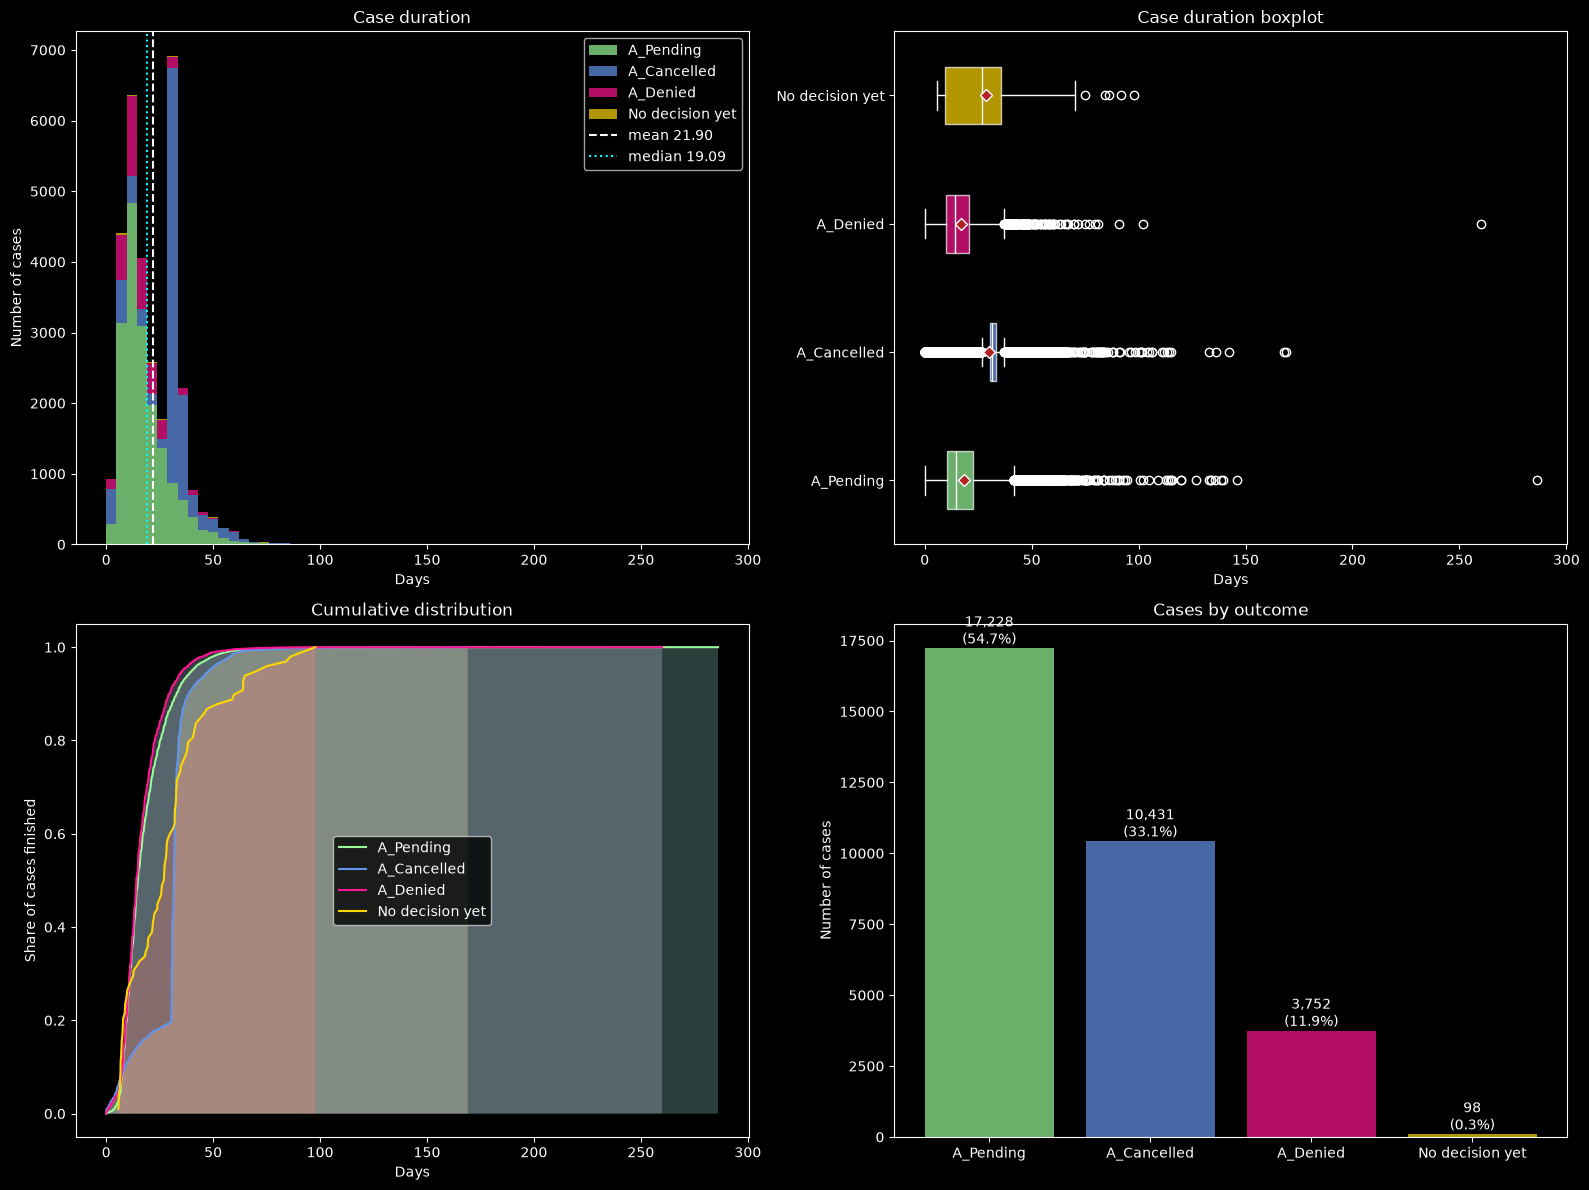

In [29]:
duration_in_days = cases["duration_days"]

plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# For the outcome
order = ["A_Pending",
         "A_Cancelled",
         "A_Denied",
         "No decision yet"]
colors = {"A_Pending": "palegreen", 
          "A_Cancelled": "cornflowerblue",
          "A_Denied": "deeppink", 
          "No decision yet": "gold"}

# It is required one duration series per outcome, in a fixed order!
groups = {o: cases.loc[cases["outcome"] == o, "duration_days"] for o in order}

# Histogram 

# To have same bin edges for every group
bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()), # a list of series, one per outcome                   
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title="Case duration",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot (one box per outcome)
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): # To pair each box with an order
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") # In order for medians to stay visible
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF - Empirical Cumulative Distribution Function (one curve per outcome)
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome

# First, we calculate the frequencies of each category
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.show()

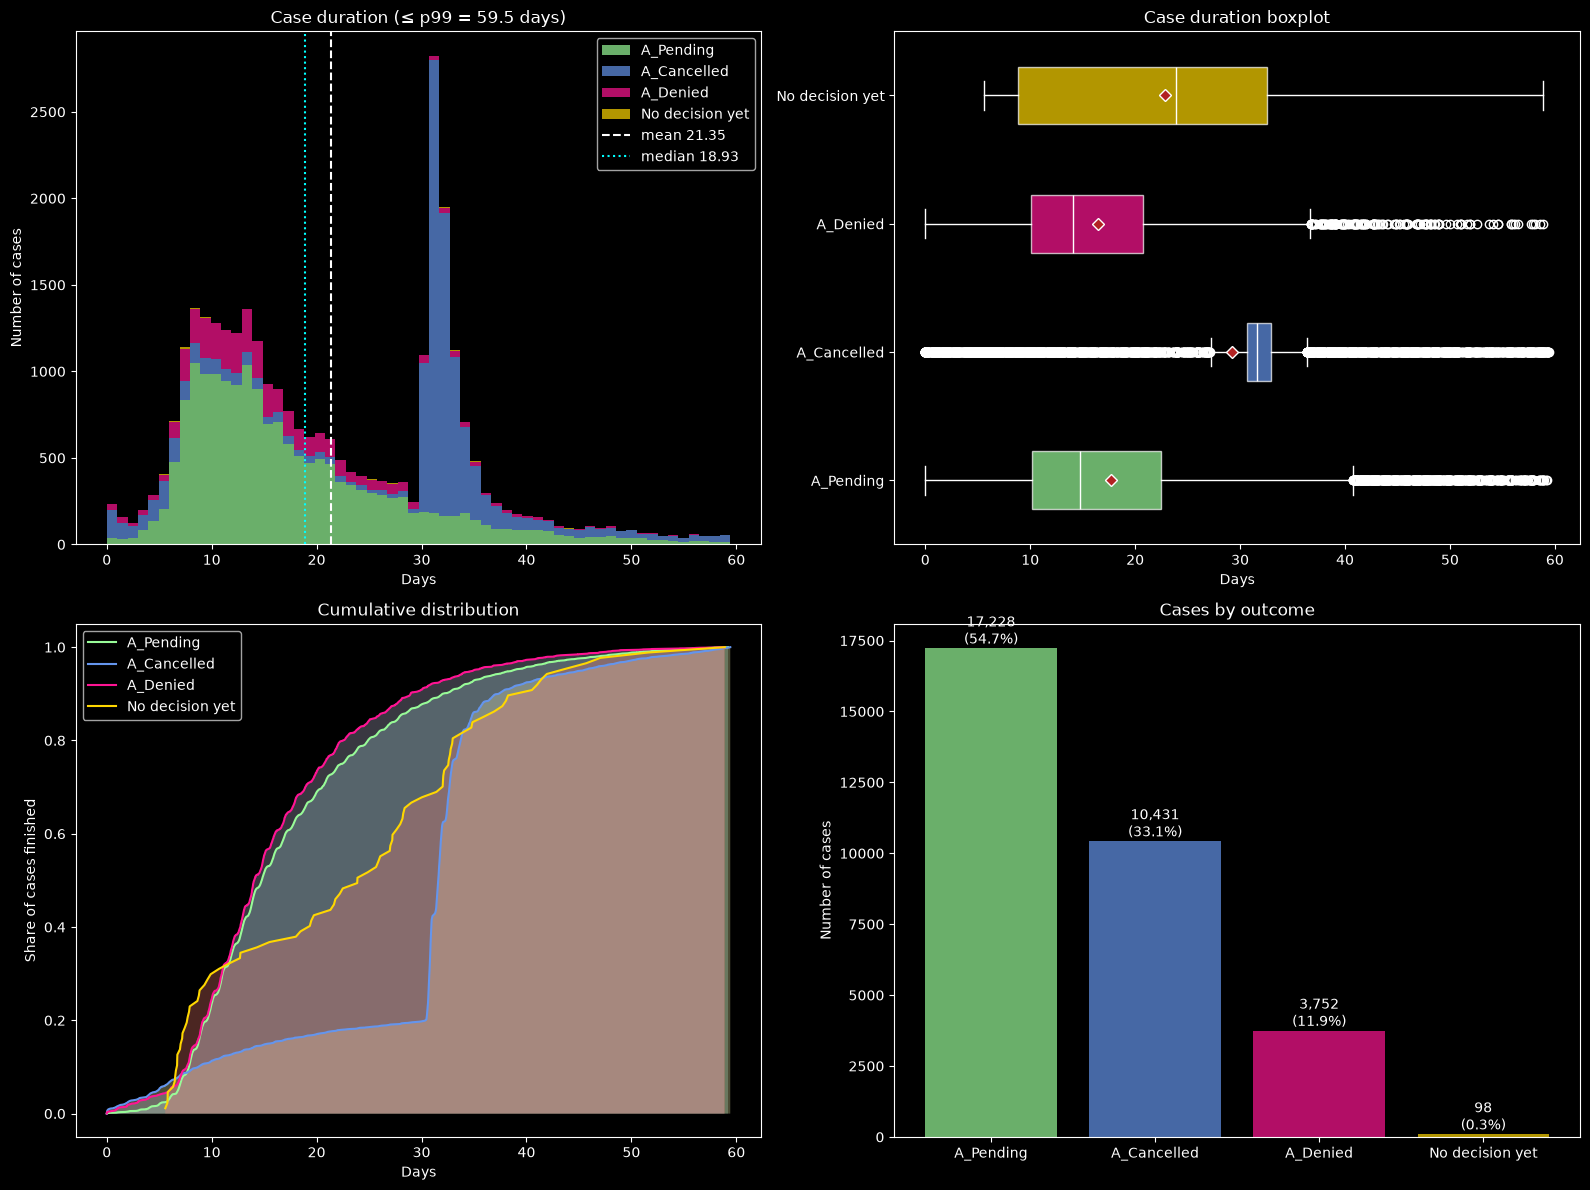

In [30]:
# NOTE: Some graphs seemed skewed so I decided to leave out some 'outliers'ArithmeticError

# So we change the range in graphs with percentil 99
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
p99 = cases["duration_days"].quantile(0.99)
shown = cases[cases["duration_days"] <= p99]
duration_in_days = shown["duration_days"]
groups = {o: shown.loc[shown["outcome"] == o, "duration_days"] for o in order}


# Everything else is the same 
# Histogram 

bins = np.histogram_bin_edges(duration_in_days, bins=60)  

axes[0][0].hist(list(groups.values()),                  
                bins=bins,
                stacked=True,
                color=[colors[o] for o in order],
                alpha=0.7,
                label=order)
axes[0][0].set(title=f"Case duration (≤ p99 = {p99:.1f} days)",
               xlabel="Days",
               ylabel="Number of cases")
axes[0][0].axvline(duration_in_days.mean(),
                   linestyle="--",
                   color="white",                          
                   label=f"mean {duration_in_days.mean():.2f}")
axes[0][0].axvline(duration_in_days.median(),
                   linestyle=":",
                   color="cyan",                          
                   label=f"median {duration_in_days.median():.2f}")
axes[0][0].legend()

# Boxplot 
meanpointprops = dict(marker='D',
                      markeredgecolor="white",
                      markerfacecolor="firebrick")
bp = axes[0][1].boxplot(list(groups.values()),
                        tick_labels=order,               
                        meanprops=meanpointprops,
                        showmeans=True,
                        meanline=False, 
                        orientation="horizontal",
                        patch_artist=True)


for patch, o in zip(bp["boxes"], order): 
    patch.set_facecolor(colors[o])
    patch.set_alpha(0.7)
for median in bp["medians"]:
    median.set_color("white") 
axes[0][1].set(title="Case duration boxplot", xlabel="Days")

# ECDF 
for o in order:
    x = np.sort(groups[o].values)
    y = np.arange(1, len(x) + 1) / len(x)
    axes[1][0].plot(x, 
                    y, 
                    color=colors[o], 
                    label=o)
    axes[1][0].fill_between(x,y, alpha=0.3)
axes[1][0].set(title="Cumulative distribution",
               xlabel="Days",
               ylabel="Share of cases finished")
axes[1][0].legend()

# Cases by outcome
counts = cases["outcome"].value_counts().reindex(order) 
axes[1][1].bar(order, 
               counts.values, 
               color=[colors[o] for o in order],
               alpha=0.7)
for i, v in enumerate(counts.values):
    axes[1][1].text(i, v, f"{v:,}\n({v/len(cases):.1%})", ha="center", va="bottom")
axes[1][1].set(title="Cases by outcome", 
               ylabel="Number of cases")

plt.tight_layout()
plt.savefig("../generated_files/Case_duration_and_outcome_distribution.pdf", format="pdf")
plt.show()

#### **Outcome by loan attributes & by application type**

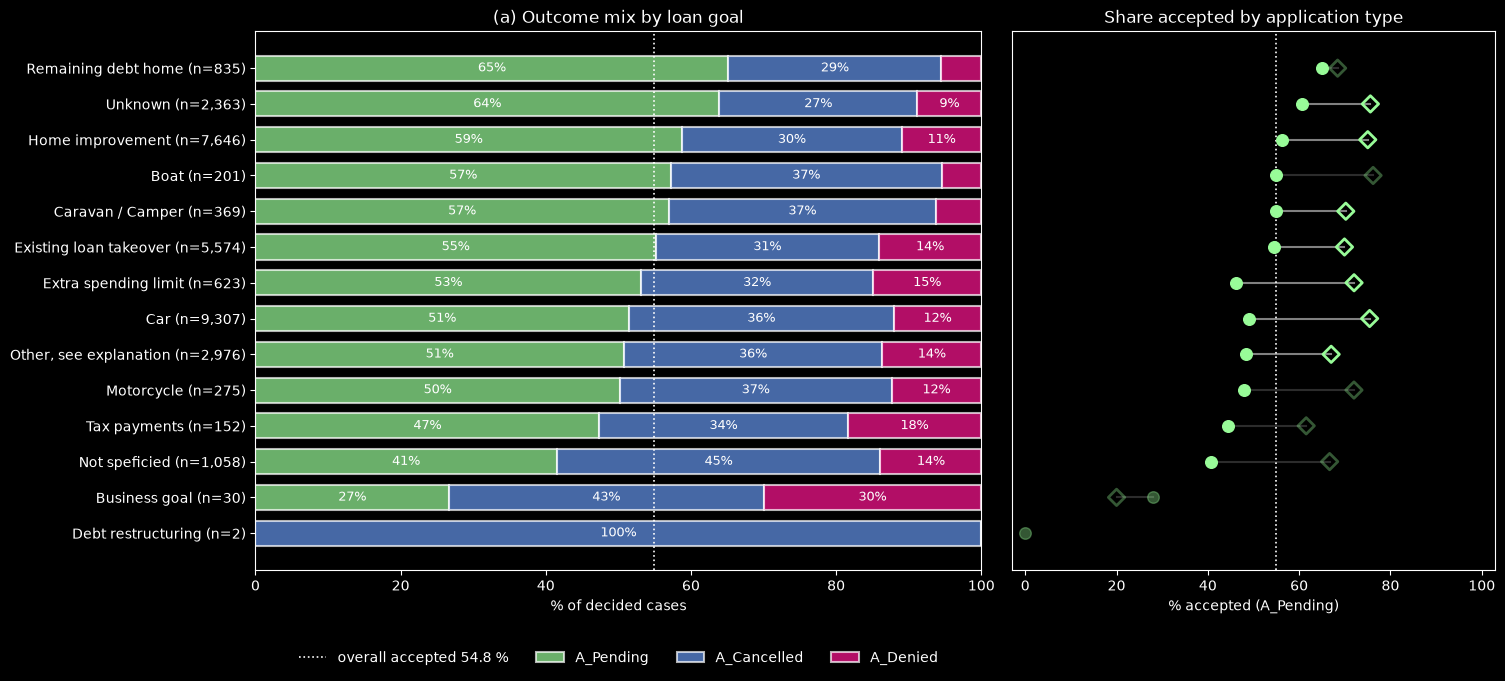

In [31]:
outcome = ["A_Pending", 
          "A_Cancelled", 
          "A_Denied"]
# Same colors to keep coherence :)
colors = {"A_Pending": "palegreen", 
          "A_Cancelled": "cornflowerblue",
          "A_Denied": "deeppink"}

# For this we must only focus on decided cases
decided_cases = cases[cases["outcome"].isin(outcome)].copy() 
decided_cases["accepted"] = decided_cases["outcome"].eq("A_Pending") # Considering cases accepted this way
decided_cases["goal"] = decided_cases["loan_goal"]  

# Resume table (cross-tabulation): otcome mix + acceptance rate per application type
mix = pd.crosstab(decided_cases["goal"], 
                  decided_cases["outcome"], 
                  normalize="index")[outcome] * 100
by_app = decided_cases.groupby(["goal", "app_type"])["accepted"].agg(["mean", "size"]).unstack("app_type")
tab = mix.assign(n=decided_cases["goal"].value_counts())
tab["accepted_new_credit"] = by_app[("mean", "New credit")] * 100
tab["accepted_limit_raise"] = by_app[("mean", "Limit raise")] * 100
tab["share_limit_raise"] = by_app[("size", "Limit raise")] / tab["n"] * 100
tab = tab.sort_values("A_Pending")    

plt.style.use("dark_background")
fig, (ax1, ax2) = plt.subplots(1, 2, 
                               figsize=(16, 7), 
                               sharey=True,
                               gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.05})
y = np.arange(len(tab))
labels = [f"{g} (n={int(n):,})" for g, n in zip(tab.index, tab["n"])]

# Stacked bars
left = np.zeros(len(tab))
for o in outcome:
    ax1.barh(y, 
             tab[o], 
             left=left, 
             color=colors[o], 
             height=0.7, 
             label=o, 
             edgecolor="white", 
             linewidth=1.5,
             alpha=0.7)
    for yi, (l, w) in enumerate(zip(left, tab[o])):
        if w >= 8:
            ax1.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9, color="white")
    left += tab[o].values

# Overall calculation
overall = decided_cases["accepted"].mean() * 100
ax1.axvline(overall, 
            color="white", 
            linestyle=":", 
            linewidth=1.2, 
            label=f"overall accepted {overall:.1f} %")
ax1.set(xlim=(0, 100),
        xlabel="% of decided cases", 
        title="(a) Outcome mix by loan goal")
ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.legend(loc="lower center", 
           bbox_to_anchor=(0.5, -0.2), 
           ncol=4, 
           frameon=False)

# Dumbbel "by application type"
# For visualization purposes dots based on fewer cases than this are drawn faded 
fade_low = 35

for yi, g in enumerate(tab.index):
    ### acceptance rates
    nc, lr = tab.loc[g, "accepted_new_credit"], tab.loc[g, "accepted_limit_raise"]
    ###
    ## sample sizes
    n_lr = by_app.loc[g, ("size", "Limit raise")]
    n_nc = by_app.loc[g, ("size", "New credit")]
    ##
    show_lr = pd.notna(lr) # NOTE: No Limit raise cases for a goal => no diamond
    show_nc = pd.notna(nc)
    a_lr = 1.0 if show_lr and n_lr >= fade_low else 0.35
    a_nc = 1.0 if show_nc and n_nc >= fade_low else 0.35
    if show_lr and show_nc:
        ax2.plot([nc, lr], [yi, yi], 
                 color="grey", 
                 linewidth=1.5, 
                 alpha=min(a_lr, a_nc), 
                 zorder=1)
    if show_lr:
        ax2.scatter(lr, yi, 
                    marker="D", 
                    s=70, 
                    facecolors="none", 
                    edgecolors=colors["A_Pending"],
                    linewidths=2, 
                    alpha=a_lr, zorder=3)
    if show_nc:
        ax2.scatter(nc, yi, 
                    marker="o", 
                    s=70, 
                    color=colors["A_Pending"], 
                    alpha=a_nc, 
                    zorder=3)
ax2.axvline(overall, 
            color="white", 
            linestyle=":", 
            linewidth=1.2)
ax2.set(xlim=(-3, 103), 
        xlabel="% accepted (A_Pending)", 
        title="Share accepted by application type")
ax2.tick_params(axis="y", left=False)

plt.savefig("../generated_files/Outcome_by_loan_attributes_by_application_type.pdf", format="pdf")
plt.show()


### **3.3 Process Model Creation and Validation**

In [32]:
# This is just a change of name because we have previously used log for original EventLog 
log_c = df[df["lifecycle:transition"] == "complete"].copy()
print(len(log_c), log_c["case:concept:name"].nunique())
log_c = log_c.sort_values([case, timestamp], kind="stable")  # NOTE: In case of draw we keep original log order


475306 31509


### **3.4 Advanced Analysis**

**IMPORTANT NOTE:** All visualizations of the nets are in an additional notebook named "Visualization_petri_nets.ipynb"

#### **Alpha Miner**

In [33]:
alpha_net, ini_mark_alpha, fin_mark_alpha = pm4py.discover_petri_net_alpha(log_c,
                                                                       activity_key=act,
                                                                       timestamp_key=timestamp,
                                                                       case_id_key=case)

# NOTE: Alpha miner has no parameters to tune so no GridSearch is required

print("Alpha model:",
      f"{len(alpha_net.places)} places,",
      f"{len(alpha_net.transitions)} transitions,",
      f"{len(alpha_net.arcs)} arcs")

# Petri net as a file
pm4py.write_pnml(alpha_net, ini_mark_alpha, fin_mark_alpha,"../generated_files/alpha_model.pnml")


Alpha model: 25 places, 24 transitions, 87 arcs


#### **Heuristic Miner**

In [34]:
# Heuristic Miner has 3 parameters: dependency_threshold, and_threshold, loop_two_threshold so we can try different values for each one

gs_heuristic = {"dependency_threshold": [0.4, 0.7],
                "and_threshold": [0.5, 0.8],
                "loop_two_threshold": [0.3, 0.75]}

# Important note, for the computation of metrics I chose token based because its faster and we are not interested in a trace-level diagnosis
best_heu_f = 0
best_heu_model = None
best_heu_params = {}

keys, values = zip(*gs_heuristic.items())

# We do all possible combiantions
combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

for params in combinations:
    try:
        heuristic_net, ini_mark_heuristics, fin_mark_heuristics = pm4py.discover_petri_net_heuristics(log_c, 
                                                                                                      activity_key=act, 
                                                                                                      timestamp_key=timestamp, 
                                                                                                      **params)
        
        fit_res = pm4py.fitness_token_based_replay(log_c, 
                                                   heuristic_net, 
                                                   ini_mark_heuristics, 
                                                   fin_mark_heuristics)
        fitness = fit_res['log_fitness']
        precision = pm4py.precision_token_based_replay(log_c, 
                                                       heuristic_net, 
                                                       ini_mark_heuristics, 
                                                       fin_mark_heuristics)
        
        # We can calculate the f_score as a representation of the trade-off between underfitting and overfitting
        f_score = 2 * (fitness * precision) / (fitness + precision) if (fitness + precision) > 0 else 0
        
        if f_score > best_heu_f: # best of the best
            best_heu_f = f_score
            best_heu_model = (heuristic_net, ini_mark_heuristics, fin_mark_heuristics)
            best_heu_params = params
            
    except Exception:
        continue

heuristic_net, ini_mark_heuristics, fin_mark_heuristics = best_heu_model

print(f"Best Heuristics Params: {best_heu_params}")
print(f"F-Score: {best_heu_f:.3f}")

print("Heuristic model:",
      f"{len(heuristic_net.places)} places,",
      f"{len(heuristic_net.transitions)} transitions,",
      f"{len(heuristic_net.arcs)} arcs")

pm4py.write_pnml(heuristic_net, ini_mark_heuristics, fin_mark_heuristics,"../generated_files/heuristics_model.pnml")


replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

...

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

Best Heuristics Params: {'dependency_threshold': 0.7, 'and_threshold': 0.8, 'loop_two_threshold': 0.75}
F-Score: 0.940
Heuristic model: 48 places, 97 transitions, 217 arcs


#### **Inductive Miner**

In [35]:
# The only parameter of inductive miner is noise_threshold
gs_inductive = {"noise_threshold": [0.0, 0.2, 0.5]}
best_ind_f = 0
best_ind_model = None

for noise in gs_inductive["noise_threshold"]:
    try:
        inductive_net, ini_mark_inductive, fin_mark_inductive = pm4py.discover_petri_net_inductive(log_c,      
                                                                                                   noise_threshold = noise,                                                                   
                                                                                                   activity_key=act,
                                                                                                   timestamp_key=timestamp,
                                                                                                   case_id_key=case)
        
        # Again using token based replay
        fit_res = pm4py.fitness_token_based_replay(log_c, inductive_net, ini_mark_inductive, fin_mark_inductive)
        fitness = fit_res['log_fitness']
        precision = pm4py.precision_token_based_replay(log_c, inductive_net, ini_mark_inductive, fin_mark_inductive)
        f_score = 2 * (fitness * precision) / (fitness + precision) if (fitness + precision) > 0 else 0
        
        if f_score > best_ind_f:
            best_ind_f = f_score
            best_ind_model = (inductive_net, ini_mark_inductive, fin_mark_inductive, noise)
            
    except Exception:
        continue

ind_net, ini_mark_ind, fin_mark_ind, best_noise = best_ind_model

print(f"Best Inductive Params: noise={best_noise}")
print(f"F-Score: {best_ind_f:.3f}")

print("Inductive model:",
      f"{len(ind_net.places)} places,",
      f"{len(ind_net.transitions)} transitions,",
      f"{len(ind_net.arcs)} arcs")


pm4py.write_pnml(ind_net, ini_mark_ind, fin_mark_ind,"../generated_files/inductive_model.pnml")

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

Best Inductive Params: noise=0.5
F-Score: 0.697
Inductive model: 23 places, 29 transitions, 64 arcs


#### **PM4Py quality metrics (fitness,precision, generalization,simplicity)**

**IMPORTANT NOTE:** Due to computational constraints, this analysis relies exclusively on token-based replay for evaluating model quality. I must admit that while token-based metrics offer a highly efficient way to calculate fitness and precision, alignment-based replay would have ultimately provided richer diagnostic value by mapping exact trace deviations to pinpoint precisely where non-conformities occur within the process.

In [36]:
# For my additional simplicity metrics I chose (NOA) Number of activities/tasks and (AGD) Average Gateway Degree, in the report I justify my decision

def noa(net):
    """
    Calculates the (NOA) Number of activities metric by counting the visible transitions (activities) 
    in a Petri net, excluding silent/invisible routing transitions.
    -------
    Params:
        - net (pm4py.objects.petri_net.obj.PetriNet): The Petri net object to evaluate.
    -------
    Return:
        - int: The total number of visible activities in the model.
    """
    noa = sum(1 for t in net.transitions if t.label is not None)
    return noa

def agd(net):
    """
    Calculates the (AGD) Average Gateway Degree metric by dividing the total number of arcs by the total 
    number of places (gateways) in the Petri net.
    -------
    Params:
        - net (pm4py.objects.petri_net.obj.PetriNet): The Petri net object to evaluate.
    -------
    Return:
        - float: The average number of incoming and outgoing arcs per place, or 0 if no places exist.
    """
    num_places = len(net.places)
    num_arcs = len(net.arcs)
    
    if num_places == 0:
        return 0
        
    agd = num_arcs / num_places
    return agd

In [37]:
# Alpha Miner - Token based Replay

# NOTE: Tried Allignment based approach and got Exception: trying to apply alignments on a Petri net that is not a easy sound net!!

# Keep only the columns that we need
log_min = log_c[[case, act, timestamp]]          

alpha_results = {}

# Fitness 
t0 = time.time()
fit = pm4py.fitness_token_based_replay(log_min, 
                                       alpha_net, 
                                       ini_mark_alpha, 
                                       fin_mark_alpha, 
                                       activity_key=act, 
                                       timestamp_key=timestamp, 
                                       case_id_key=case)
alpha_results["fitness_tbr (log_fitness)"] = fit["log_fitness"]
alpha_results["perc_fit_traces_tbr"] = fit["percentage_of_fitting_traces"] / 100
print(f"Fitness time: {time.time()-t0:.0f}s")

# Precision 
t0 = time.time()
alpha_results["precision_tbr"] = pm4py.precision_token_based_replay(log_min, 
                                                                    alpha_net, 
                                                                    ini_mark_alpha, 
                                                                    fin_mark_alpha, 
                                                                    activity_key=act, 
                                                                    timestamp_key=timestamp, 
                                                                    case_id_key=case)
print(f"Precision time: {time.time()-t0:.0f}s")

# Generalization 
t0 = time.time()
alpha_results["generalization_tbr"] = pm4py.generalization_tbr(log_min, 
                                                               alpha_net, 
                                                               ini_mark_alpha, 
                                                               fin_mark_alpha, 
                                                               activity_key=act, 
                                                               timestamp_key=timestamp, 
                                                               case_id_key=case)
print(f"Generalization: {time.time()-t0:.0f}s")

# Simplicity 
alpha_results["simplicity_pm4py"] = pm4py.simplicity_petri_net(alpha_net,  # PM4Py uses inverse arc degree
                                                               ini_mark_alpha, 
                                                               fin_mark_alpha)
# Additionals
alpha_results["NOA"] = noa(alpha_net)
alpha_results["AGD"] = agd(alpha_net)

display(pd.Series(alpha_results, name="Alpha Miner").round(3).to_frame())

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Fitness time: 20s


replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

Precision time: 82s


replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Generalization: 20s


,Alpha Miner
fitness_tbr (log_fitness),0.496
perc_fit_traces_tbr,0.000
precision_tbr,0.126
generalization_tbr,0.987
simplicity_pm4py,0.392
NOA,24.000
AGD,3.480


In [38]:
# Heuristic Miner - does allow alligned based approach, using token based for coherence in compairisons

heuristics_results = {}

# Fitness 
t0 = time.time()
fit = pm4py.fitness_token_based_replay(log_min, 
                                       heuristic_net, 
                                       ini_mark_heuristics,
                                       fin_mark_heuristics, 
                                       activity_key=act, 
                                       timestamp_key=timestamp, 
                                       case_id_key=case)
heuristics_results["fitness_tbr (log_fitness)"] = fit["log_fitness"]
heuristics_results["perc_fit_traces_tbr"] = fit["percentage_of_fitting_traces"] / 100
print(f"Fitness time: {time.time()-t0:.0f}s")

# Precision 
t0 = time.time()
heuristics_results["precision_tbr"] = pm4py.precision_token_based_replay(log_min, 
                                                                         heuristic_net, 
                                                                         ini_mark_heuristics, 
                                                                         fin_mark_heuristics, 
                                                                         activity_key=act, 
                                                                         timestamp_key=timestamp, 
                                                                         case_id_key=case)
print(f"Precision time: {time.time()-t0:.0f}s")

# Generalization
t0 = time.time()
heuristics_results["generalization_tbr"] = pm4py.generalization_tbr(log_min, 
                                                                    heuristic_net, 
                                                                    ini_mark_heuristics, 
                                                                    fin_mark_heuristics, 
                                                                    activity_key=act, 
                                                                    timestamp_key=timestamp, 
                                                                    case_id_key=case)
print(f"Generalization time: {time.time()-t0:.0f}s")

# Simplicity
heuristics_results["simplicity_pm4py"] = pm4py.simplicity_petri_net(heuristic_net, 
                                                                    ini_mark_heuristics, 
                                                                    fin_mark_heuristics)
heuristics_results["NOA"] = noa(heuristic_net)
heuristics_results["AGD"] = agd(heuristic_net)

display(pd.Series(heuristics_results, name="Heuristics Miner").round(3).to_frame())

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Fitness time: 48s


replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

Precision time: 64s


replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Generalization time: 41s


,Heuristics Miner
fitness_tbr (log_fitness),0.897
perc_fit_traces_tbr,0.000
precision_tbr,0.987
generalization_tbr,0.880
simplicity_pm4py,0.502
NOA,24.000
AGD,4.521


In [39]:
# Inductive Miner

inductive_results = {}

# Fitness #ind_net, ini_mark_ind, fin_mark_ind
t0 = time.time()
fit = pm4py.fitness_token_based_replay(log_min, 
                                       ind_net, 
                                       ini_mark_ind, 
                                       fin_mark_ind,
                                       activity_key=act, 
                                       timestamp_key=timestamp, 
                                       case_id_key=case)
inductive_results["fitness_tbr (log_fitness)"] = fit["log_fitness"]
inductive_results["perc_fit_traces_tbr"] = fit["percentage_of_fitting_traces"] / 100
print(f"Fitness time: {time.time()-t0:.0f}s")

# Precision (token-based, ETConformance)
t0 = time.time()
inductive_results["precision_tbr"] = pm4py.precision_token_based_replay(log_min, 
                                                                        ind_net, 
                                                                        ini_mark_ind, 
                                                                        fin_mark_ind, 
                                                                        activity_key=act, 
                                                                        timestamp_key=timestamp, 
                                                                        case_id_key=case)
print(f"Precision time: {time.time()-t0:.0f}s")

# Generalization
t0 = time.time()
inductive_results["generalization_tbr"] = pm4py.generalization_tbr(log_min, 
                                                                   ind_net, 
                                                                   ini_mark_ind, 
                                                                   fin_mark_ind,
                                                                   activity_key=act, 
                                                                   timestamp_key=timestamp, 
                                                                   case_id_key=case)
print(f"Generalization time: {time.time()-t0:.0f}s")

# Simplicity
inductive_results["simplicity_pm4py"] = pm4py.simplicity_petri_net(ind_net, 
                                                                   ini_mark_ind, 
                                                                   fin_mark_ind)
inductive_results["NOA"] = noa(inductive_net)
inductive_results["AGD"] = agd(inductive_net)

display(pd.Series(inductive_results, name="Inductive Miner").round(3).to_frame())

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Fitness time: 19s


replaying log with TBR, completed traces ::   0%|          | 0/27816 [00:00<?, ?it/s]

Precision time: 40s


replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Generalization time: 19s


,Inductive Miner
fitness_tbr (log_fitness),0.886
perc_fit_traces_tbr,0.025
precision_tbr,0.574
generalization_tbr,0.835
simplicity_pm4py,0.684
NOA,16.000
AGD,2.783


### **Final process model**

In [40]:
# As requested in the assignment our goal will be to take perc_fit_traces_tbr above 0.8.
# For that we will take our best model (Inductive) and continue with it from now on. 

# We can identify the amount of variants we have in the log

# Extract all trace variants 
variants = pm4py.get_variants(log_c,
                              activity_key=act,
                              timestamp_key=timestamp,
                              case_id_key=case)
# Frequency of each variant
variant_counts = pd.DataFrame([{"trace": variant,"frequency": frequency} for variant, frequency in variants.items()])

# Sort variants by frequency
variant_counts = (variant_counts.sort_values("frequency", ascending=False).reset_index(drop=True))

# Percentages and cumulative coverage
total_cases = log_c[case].nunique()

variant_counts["percentage"] = (variant_counts["frequency"] / total_cases * 100)

variant_counts["cumulative_percentage"] = (variant_counts["percentage"].cumsum())

# This line is just to make readable the variant representations
variant_counts["variant"] = variant_counts["trace"].apply(lambda x: " → ".join(x) if isinstance(x, (tuple, list)) else str(x))


num_variants = len(variant_counts)
print(f"Total cases: {total_cases:,}")
print(f"Unique trace variants: {num_variants:,}")

# Top 20 variants
display(variant_counts[["variant", "frequency", "percentage", "cumulative_percentage"]].head(20).round(2))

# Coverage of Top 10 variants
top_10_coverage = (variant_counts.head(10)["frequency"].sum()/ total_cases * 100)

# IMPORTANT: Number of variants needed to cover 80% of cases
variants_for_80 = (variant_counts["cumulative_percentage"].ge(80).idxmax() + 1)

print(f"\nCoverage of top 10 variants: {top_10_coverage:.2f}%")
print(f"Variants needed for 80% coverage: {variants_for_80}")

Total cases: 31,509
Unique trace variants: 5,623


,variant,frequency,percentage,cumulative_percentage
0,A_Create Application → A_Submitted → A_Concept...,2209,7.01,7.01
1,A_Create Application → A_Submitted → A_Concept...,1917,6.08,13.09
2,A_Create Application → A_Concept → A_Accepted ...,1578,5.01,18.10
3,A_Create Application → A_Concept → A_Accepted ...,969,3.08,21.18
4,A_Create Application → A_Submitted → A_Concept...,676,2.15,23.32
5,A_Create Application → A_Submitted → A_Concept...,621,1.97,25.29
6,A_Create Application → A_Submitted → A_Concept...,490,1.56,26.85
7,A_Create Application → A_Submitted → W_Handle ...,470,1.49,28.34
8,A_Create Application → A_Submitted → W_Handle ...,448,1.42,29.76
9,A_Create Application → A_Submitted → A_Concept...,439,1.39,31.16



Coverage of top 10 variants: 31.16%
Variants needed for 80% coverage: 610


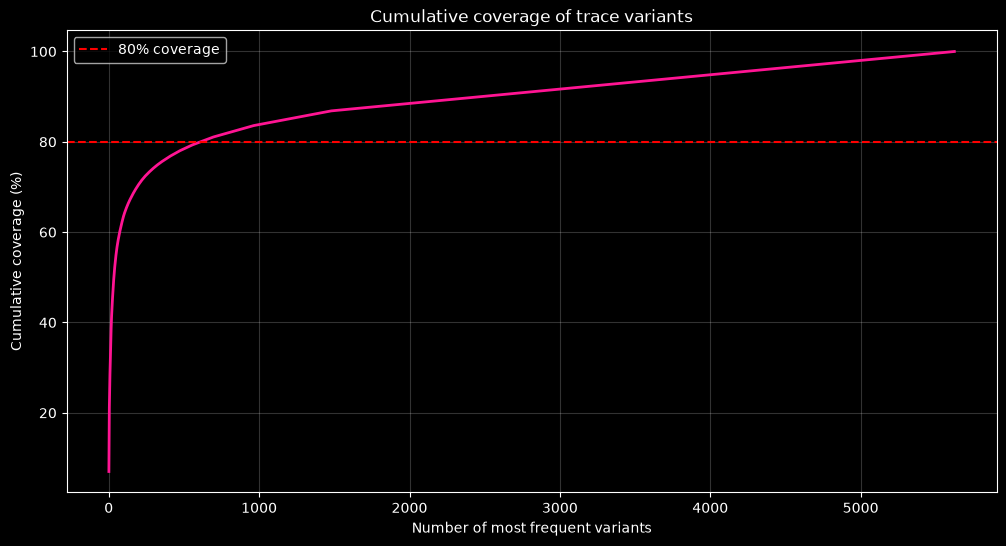

In [41]:
# Just to visualize the cumulative coverage of trace variants

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(np.arange(1, len(variant_counts) + 1),
        variant_counts["cumulative_percentage"],
        linewidth=2,
        color="deeppink")
ax.axhline(80, color="red", linestyle="--", label="80% coverage")
ax.set(xlabel="Number of most frequent variants",
       ylabel="Cumulative coverage (%)",
       title="Cumulative coverage of trace variants")
ax.legend()
ax.grid(alpha=0.2)
plt.savefig("../generated_files/Cumulative_coverage_of_trace_variants.pdf", format="pdf")
plt.show()

In [42]:
# NOTE: If we try to manually incorporate all 610 variants into our process model that would potentially create an enormous and 
# complicated model, sacrificing precision and simplicity. Instead, I propose investigate why the existing Inductive Miner model 
# fails to replay these variants perfectly.

# This performs Token-based replay diagnostics using our best Inductive Miner model (till now :)) )


event_log = pm4py.convert_to_event_log(log_c,
                                       case_id_key=case,
                                       activity_key=act,
                                       timestamp_key=timestamp)


replay_diagnostics = pm4py.conformance_diagnostics_token_based_replay(event_log,
                                                                      ind_net,
                                                                      ini_mark_ind,
                                                                      fin_mark_ind,
                                                                      activity_key=act)

print(f"Total traces replayed: {len(replay_diagnostics)}")
print(f"Total cases in event log: {len(event_log)}")

replaying log with TBR, completed traces ::   0%|          | 0/5623 [00:00<?, ?it/s]

Total traces replayed: 31509
Total cases in event log: 31509


In [43]:
# Now, we should combine the replay diagnostics with the corresponding activity sequences.

replay_results = [] # One record per case

for trace_obj, diagnostics in zip(event_log, replay_diagnostics):

    case_id = trace_obj.attributes.get("concept:name",trace_obj.attributes.get(case))
    trace_variant = tuple(event[act] for event in trace_obj)

    replay_results.append({"case_id": case_id,
                           "trace": trace_variant,
                           "trace_is_fit": diagnostics["trace_is_fit"],
                           "trace_fitness": diagnostics["trace_fitness"],
                           "missing_tokens": diagnostics["missing_tokens"],
                           "remaining_tokens": diagnostics["remaining_tokens"],
                           "consumed_tokens": diagnostics["consumed_tokens"],
                           "produced_tokens": diagnostics["produced_tokens"]})

replay_df = pd.DataFrame(replay_results)

display(replay_df.head())


,case_id,trace,trace_is_fit,trace_fitness,missing_tokens,remaining_tokens,consumed_tokens,produced_tokens
0,Application_1000086665,"(A_Create Application, A_Submitted, A_Concept,...",False,0.818182,2,2,11,11
1,Application_1000158214,"(A_Create Application, A_Submitted, A_Concept,...",False,0.904762,2,2,21,21
2,Application_1000311556,"(A_Create Application, A_Concept, A_Accepted, ...",False,0.818182,2,2,11,11
3,Application_1000334415,"(A_Create Application, A_Submitted, A_Concept,...",False,0.888043,1,4,20,23
4,Application_1000339879,"(A_Create Application, A_Submitted, A_Concept,...",True,1.000000,0,0,29,29


In [44]:
# Aggregate replay results by trace variant

variant_replay = (replay_df.groupby("trace").agg(frequency=("case_id", "count"),
                                                 fitting_cases=("trace_is_fit", "sum"),
                                                 avg_fitness=("trace_fitness", "mean"),
                                                 missing_tokens=("missing_tokens", "sum"),
                                                 remaining_tokens=("remaining_tokens", "sum")).reset_index())

# Non-fitting cases
variant_replay["non_fitting_cases"] = (variant_replay["frequency"] - variant_replay["fitting_cases"])

# Percentage of cases belonging to each variant
variant_replay["percentage"] = (variant_replay["frequency"] / len(replay_df) * 100)

# Percentage of non-fitting cases within each variant
variant_replay["non_fitting_percentage"] = (variant_replay["non_fitting_cases"] / variant_replay["frequency"] * 100)

# Just to make readable the trace
variant_replay["variant"] = variant_replay["trace"].apply(lambda x: " → ".join(x))

# Sort by number of non-fitting cases
variant_replay = (variant_replay.sort_values("non_fitting_cases", ascending=False).reset_index(drop=True))

display(variant_replay[["variant",
                        "frequency",
                        "fitting_cases",
                        "non_fitting_cases",
                        "percentage",
                        "avg_fitness",
                        "missing_tokens",
                        "remaining_tokens"]].head(20).round(3))


,variant,frequency,fitting_cases,non_fitting_cases,percentage,avg_fitness,missing_tokens,remaining_tokens
0,A_Create Application → A_Submitted → A_Concept...,2209,0,2209,7.011,0.923,2209,2209
1,A_Create Application → A_Submitted → A_Concept...,1917,0,1917,6.084,0.818,3834,3834
2,A_Create Application → A_Concept → A_Accepted ...,1578,0,1578,5.008,0.818,3156,3156
3,A_Create Application → A_Concept → A_Accepted ...,969,0,969,3.075,0.842,2907,2907
4,A_Create Application → A_Submitted → A_Concept...,676,0,676,2.145,0.842,2028,2028
5,A_Create Application → A_Submitted → A_Concept...,621,0,621,1.971,0.905,1242,1242
6,A_Create Application → A_Submitted → A_Concept...,490,0,490,1.555,0.900,980,980
7,A_Create Application → A_Submitted → W_Handle ...,470,0,470,1.492,0.818,940,940
8,A_Create Application → A_Submitted → W_Handle ...,448,0,448,1.422,0.923,448,448
9,A_Create Application → A_Submitted → A_Concept...,439,0,439,1.393,0.909,878,878


In [45]:
# Actual percentage of perfectly fitting traces

fitting_cases = replay_df["trace_is_fit"].sum()
total_cases = len(replay_df)
perc_fit = fitting_cases / total_cases
print(f"Total cases: {total_cases:,}")
print(f"Perfectly fitting cases: {fitting_cases:,}")
print(f"Non-fitting cases: {total_cases - fitting_cases:,}")
print(f"Percentage of fitting traces: {perc_fit:.4f}")


Total cases: 31,509
Perfectly fitting cases: 780
Non-fitting cases: 30,729
Percentage of fitting traces: 0.0248


In [46]:
# Most important variants to investigate
# Select variants where none of their cases fit perfectly
problematic_variants = (variant_replay[variant_replay["fitting_cases"] == 0].sort_values("frequency", ascending=False).reset_index(drop=True))

# Cumulative coverage of problematic variants
problematic_variants["cumulative_non_fitting"] = (problematic_variants["frequency"].cumsum() / (total_cases - fitting_cases) * 100)

print(f"Number of variants with zero fitting cases: "f"{len(problematic_variants)}")

display(problematic_variants[["variant",
                              "frequency",
                              "percentage",
                              "missing_tokens",
                              "remaining_tokens",
                              "cumulative_non_fitting"]].head(20).round(3))


Number of variants with zero fitting cases: 5472


,variant,frequency,percentage,missing_tokens,remaining_tokens,cumulative_non_fitting
0,A_Create Application → A_Submitted → A_Concept...,2209,7.011,2209,2209,7.189
1,A_Create Application → A_Submitted → A_Concept...,1917,6.084,3834,3834,13.427
2,A_Create Application → A_Concept → A_Accepted ...,1578,5.008,3156,3156,18.562
3,A_Create Application → A_Concept → A_Accepted ...,969,3.075,2907,2907,21.716
4,A_Create Application → A_Submitted → A_Concept...,676,2.145,2028,2028,23.916
5,A_Create Application → A_Submitted → A_Concept...,621,1.971,1242,1242,25.936
6,A_Create Application → A_Submitted → A_Concept...,490,1.555,980,980,27.531
7,A_Create Application → A_Submitted → W_Handle ...,470,1.492,940,940,29.060
8,A_Create Application → A_Submitted → W_Handle ...,448,1.422,448,448,30.518
9,A_Create Application → A_Submitted → A_Concept...,439,1.393,878,878,31.947


In [47]:
# decision variables, obviously can change 
coverage_grid = [0.80, 0.85] # [0.75, 0.80, 0.85] # := share of cases whose variants are kept for discovery
noise_grid = [0.0, 0.05, 0.1] #[0.55, 0.45, 0.5] # noise threshold close to the one we already chose
target_replay= 0.80          
tolerance_acceptance = 0.02 # accept >= 0.78

In [48]:
# Relevant decision #1: what do we model?

log_base = log_c[[case, act, timestamp]]
# I decided to drop the open cases ("No decision yet") which were truncated traces
open_cases = cases.index[cases["outcome"] == "No decision yet"]
log_base = log_base[~log_base[case].isin(open_cases)]
 
n_cases_base = log_base[case].nunique()
print(f"Cases in base log: {n_cases_base:,}")

Cases in base log: 31,411


In [49]:
# Relevant decision #2: which behaviour is "main behaviour"?
trace_of_case = log_base.groupby(case, sort=False)[act].agg(tuple) # one tuple of activities per case
variant_freq = trace_of_case.value_counts() # sorted => most frequent first
cum_cov = variant_freq.cumsum() / variant_freq.sum()
 
print(f"Variants in base log: {len(variant_freq):,}")

Variants in base log: 5,562


In [50]:
# Auxiliar function 3
def filter_top_variants(coverage):
    """
    Filters the event log to keep only the cases belonging to the most frequent process variants required to reach a 
    specified target coverage of all cases.
    -------
    Params:
        - coverage (float): The target proportion of cases to cover [0,1].
    -------
    Return:
        - tuple: A tuple containing the filtered event log (pandas.DataFrame), the number of top variants kept (int),
          and the actual case coverage achieved (float).
    """
    k = int((cum_cov < coverage).sum()) + 1
    kept_variants = set(variant_freq.index[:k])
    kept_cases = trace_of_case.index[trace_of_case.isin(kept_variants)]
    filtered = log_base[log_base[case].isin(kept_cases)]
    return filtered, k, len(kept_cases) / n_cases_base

In [51]:
# # Auxiliar function 4: The following is to call in a single line the miner, as I will be calling it many times
def discover(log_df, noise):
    """
    Discovers a process tree using the Inductive Miner algorithm and converts it into a Petri net.
    -------
    Params:
        - log_df (pandas.DataFrame): The event log used for process discovery.
        - noise (float): The noise threshold applied during inductive mining to filter infrequent behavior.
    -------
    Return:
        - tuple: A tuple containing the discovered process tree, the converted Petri net, the initial marking, and the final marking.
    """
    tree = pm4py.discover_process_tree_inductive(log_df, 
                                                 noise_threshold=noise, 
                                                 activity_key=act, 
                                                 timestamp_key=timestamp, 
                                                 case_id_key=case)
    net, im, fm = pm4py.convert_to_petri_net(tree)
    return tree, net, im, fm

In [52]:
# Auxiliar function 5: Same as the past function. Just to make the call of multiple functions in a single line
def evaluate(net, im,  fm, log_eval, alignments=False):
    """
    Computes quality and simplicity metrics for a discovered Petri net against an evaluation log, utilizing token-based replay by default.
    -------
    Params:
        - net (pm4py.objects.petri_net.obj.PetriNet): The Petri net to evaluate.
        - im (pm4py.objects.petri_net.obj.Marking): The initial marking of the Petri net.
        - fm (pm4py.objects.petri_net.obj.Marking): The final marking of the Petri net.
        - log_eval (pandas.DataFrame): The event log used for evaluation (always the full base log, never the filtered one).
        - alignments (bool, optional): If True, additionally computes alignment-based fitness and precision. Defaults to False.
    -------
    Return:
        - dict: A dictionary containing the computed metrics (fitness, precision, generalization, simplicity, NOA, and AGD).
    """
    res = {}
    fit = pm4py.fitness_token_based_replay(log_eval, 
                                           net, 
                                           im, 
                                           fm, 
                                           activity_key=act, 
                                           timestamp_key=timestamp, 
                                           case_id_key=case)
    res["fitness_tbr"] = fit["log_fitness"]
    res["fit_traces_tbr"] = fit["percentage_of_fitting_traces"] / 100
    res["precision_tbr"] = pm4py.precision_token_based_replay(log_eval, 
                                                              net, 
                                                              im, 
                                                              fm, 
                                                              activity_key=act, 
                                                              timestamp_key=timestamp, 
                                                              case_id_key=case)
    res["generalization_tbr"] = pm4py.generalization_tbr(log_eval, 
                                                         net, 
                                                         im, 
                                                         fm, 
                                                         activity_key=act, 
                                                         timestamp_key=timestamp, 
                                                         case_id_key=case)
    res["simplicity"] = pm4py.simplicity_petri_net(net, 
                                                   im, 
                                                   fm)
    res["NOA"] = noa(net)
    res["AGD"] = agd(net)
    if alignments:
        al = pm4py.fitness_alignments(log_eval, 
                                      net, 
                                      im, 
                                      fm, 
                                      activity_key=act, 
                                      timestamp_key=timestamp, 
                                      case_id_key=case)
        res["fitness_align"] = al["log_fitness"]
        res["fit_traces_align"] = al["percentage_of_fitting_traces"] / 100
        res["precision_align"] = pm4py.precision_alignments(log_eval, 
                                                            net, 
                                                            im, 
                                                            fm, 
                                                            activity_key=act, 
                                                            timestamp_key=timestamp, 
                                                            case_id_key=case)
    return res
 
 

In [ ]:
# The following iterations constitute my "refinements" to the model
rows, models = [], {}
 
for cov in coverage_grid :
    filtered, k, real_cov = filter_top_variants(cov)
    for noise in noise_grid:
        tree, net, im, fm = discover(filtered, noise)
        metrics = evaluate(net, im, fm, log_base) 
        rows.append({"coverage": cov, "variants_kept": k, "noise": noise, **metrics})
        models[(cov, noise)] = (tree, net, im, fm)
        print(f"coverage={cov:.2f} noise={noise:.1f} -> "
              f"fit traces={metrics['fit_traces_tbr']:.3f}, precision={metrics['precision_tbr']:.3f}, "
              f"NOA={metrics['NOA']}")
 
iterations = pd.DataFrame(rows).round(3)
iterations.to_csv(f"../generated_files/iterations1.csv", index=False)
display(iterations)

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

In [ ]:
# Relevant decision #3: which metric wins?

# Rules: 1. keep only models that reach the target_replay
#        2. prefer PRECISION, then SIMPLICITY (justified in report)

eligible = iterations[iterations["fit_traces_tbr"] >= target_replay - tolerance_acceptance]
 
if eligible.empty: # No iteration reaches the target, which could lead to raise coverage or lower noise
    print("No iteration reaches the target :'( so taking the one closest to it.")
    best_row = iterations.sort_values("fit_traces_tbr", ascending=False).iloc[0]
else:
    best_row = eligible.sort_values(["precision_tbr", "simplicity"], ascending=False).iloc[0]
 
best_key = (best_row["coverage"], best_row["noise"])
tree, net, im, fm = models[best_key]
print(f"Chosen: coverage={best_row['coverage']:.2f}, variants_kept={int(best_row['variants_kept'])}, noise={best_row['noise']:.2f}")
# print(tree) 

Chosen: coverage=0.85, variants_kept=1156, noise=0.05


In [ ]:
# NOTE: Alignments are feasible because the net is sound! (this will take a while)

final_metrics = evaluate(net, im, fm, log_base, alignments=True)
final_metrics_df = pd.Series(final_metrics, name="Final model").round(3).to_frame()
final_metrics_df.to_csv(f"../generated_files/final_model_metrics.csv")
display(final_metrics_df)

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/5562 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/27735 [00:00<?, ?it/s]

In [ ]:
# BPMN 2.0 is generated in the visualization notebook
pm4py.write_pnml(net, im, fm, f"../generated_files/final_model.pnml")

# We save the tree 
pm4py.write_ptml(tree, "../generated_files/final_model.ptml")